In [1]:
"""
Titanic Data Analysis and JSON Export
Author: [Momina]
Description: Analyze Titanic passenger data, engineer features, and export to JSON
"""
 
import pandas as pd
import numpy as np
import json
from pathlib import Path
 
# Set up paths
DATA_DIR = Path("data")
CSV_FILE = DATA_DIR / "titanic.csv"
JSON_FILE = DATA_DIR / "titanic_processed.json"
 
# Create data directory if it doesn't exist
DATA_DIR.mkdir(exist_ok=True)
 
print("Project setup complete!")
print(f"Data directory: {DATA_DIR}")
print(f"CSV file location: {CSV_FILE}")

Project setup complete!
Data directory: data
CSV file location: data\titanic.csv


Imported the libraries for working with the data, handling file paths, and exporting to JSON. I set the locations of the input CSV and output JSON, then made sure the `data` folder existed.

In [3]:
%pip install pandas numpy

Note: you may need to restart the kernel to use updated packages.


In [4]:

%pip install seaborn
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


installed pandas and NumPy in the Python environment used by the notebook. I use pandas to load the CSV and work with the passenger data as a table.

In [5]:
df = pd.read_csv(CSV_FILE)

print(f"Dataset loaded successfully! Shape: {df.shape}")
print(f"\nColumns: {list(df.columns)}")
print("\nFirst few rows:")
print(df.head())

Dataset loaded successfully! Shape: (891, 12)

Columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

First few rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 175

Load Dataset

Loaded the Titanic CSV into a pandas DataFrame called `df`. I checked that it had 891 rows and 12 columns, then displayed the column names and the first five rows to see how the data was organized.

In [6]:
# Step 3: Select numeric columns only
numeric_columns = df.select_dtypes(include="number").columns
# Calculate statistics (.mean, median, std)
mean_values = df[numeric_columns].mean()
median_values = df[numeric_columns].median()
std_values = df[numeric_columns].std()

print (mean_values)
print (median_values)
print (std_values)

PassengerId    446.000000
Survived         0.383838
Pclass           2.308642
Age             29.699118
SibSp            0.523008
Parch            0.381594
Fare            32.204208
dtype: float64
PassengerId    446.0000
Survived         0.0000
Pclass           3.0000
Age             28.0000
SibSp            0.0000
Parch            0.0000
Fare            14.4542
dtype: float64
PassengerId    257.353842
Survived         0.486592
Pclass           0.836071
Age             14.526497
SibSp            1.102743
Parch            0.806057
Fare            49.693429
dtype: float64


Calculating desciptive statistics (mean, median, mode)

I selected the numeric columns and calculated the mean, median, and standard deviation for each one. The mean gives the average, the median gives the middle value, and the standard deviation shows how spread out the values are.

In [7]:
# Step 4: Count missing values
print("\n" + "="*50)
print("MISSING VALUES ANALYSIS")
print("="*50)
 
missing_data = {}
 
for col in df.columns:
    missing_count = df[col].isnull().sum()
    missing_percent = (missing_count / len(df)) * 100
    if missing_count > 0:
        missing_data[col] = {
            "missing_count": missing_count,
            "missing_percent": missing_percent
        }
# Display missing values analysis 
for col, data in missing_data.items():
        print (f"Column: {col}, Missing Count: {data['missing_count']}, Missing Percent: {data['missing_percent']:.2f}%")






MISSING VALUES ANALYSIS
Column: Age, Missing Count: 177, Missing Percent: 19.87%
Column: Cabin, Missing Count: 687, Missing Percent: 77.10%
Column: Embarked, Missing Count: 2, Missing Percent: 0.22%


Checking for missing values

Counted the missing values in each column and calculated the percentage of rows affected. `Cabin` had the most missing values at 77.10%, followed by `Age` at 19.87% and `Embarked` at 0.22%.

In [8]:
# Create engineered features
## Feature 1: Family Size
df_features = df.copy()
df_features['FamilySize'] = df_features['SibSp'] + df_features['Parch'] + 1
print(df_features[['SibSp', 'Parch', 'FamilySize']].head(10))

# Feature 2: Is Alone
df_features['IsAlone'] = (df_features['FamilySize'] == 1).astype(int) #astype makes the column binary
print(df_features[['FamilySize', 'IsAlone']].head(10))

# Feature 3: Age Groups
def categorize_age(age):
    """Categorize age into groups"""
    if pd.isna(age):
        return 'Unknown'
    elif age < 18:
        return 'under 18'
    elif age < 30:
        return 'under 30    '
    elif age < 50:
        return 'under 50    '
    else:
        return '50 and over   '

df_features['AgeGroup'] = df_features['Age'].apply(categorize_age)
print(df_features[['Age', 'AgeGroup']].head(10))


 


   SibSp  Parch  FamilySize
0      1      0           2
1      1      0           2
2      0      0           1
3      1      0           2
4      0      0           1
5      0      0           1
6      0      0           1
7      3      1           5
8      0      2           3
9      1      0           2
   FamilySize  IsAlone
0           2        0
1           2        0
2           1        1
3           2        0
4           1        1
5           1        1
6           1        1
7           5        0
8           3        0
9           2        0
    Age        AgeGroup
0  22.0    under 30    
1  38.0    under 50    
2  26.0    under 30    
3  35.0    under 50    
4  35.0    under 50    
5   NaN         Unknown
6  54.0  50 and over   
7   2.0        under 18
8  27.0    under 30    
9  14.0        under 18


Created Engineered features (familysize, alone, age group)

Made a copy of the passenger data and added three columns. `FamilySize` counts the passenger plus their siblings, spouses, parents, and children on board. `IsAlone` is 1 when that count is 1 and 0 otherwise, while `AgeGroup` puts passengers into age ranges and labels missing ages as `Unknown`.

In [9]:
# Analyze feature differences between survivors and non-survivors.
"""Among the passengers who survived, what were their average and middle family sizes, 
and how much did those sizes vary? And what were those same figures for passengers who did not survive?"""


print("\n" + "="*50)
print("FEATURE ANALYSIS: SURVIVED vs NOT SURVIVED")
print("="*50)

# 
print("\nFamily Size by Survival:")
family_survival = df_features.groupby('Survived')['FamilySize'].agg(['mean', 'median', 'std'])
print(family_survival)

# Descriptive comparison of survivors and non-survivors
print("\n" + "="*50)
print("FEATURE DIFFERENTIATION ANALYSIS")
print("="*50)


survived = df_features[df_features['Survived'] == 1]
not_survived = df_features[df_features['Survived'] == 0]
 
print("\nFamily Size:")
print(f"  Survived mean: {survived['FamilySize'].mean():.2f}")
print(f"  Not Survived mean: {not_survived['FamilySize'].mean():.2f}")
print(f"  Difference: {abs(survived['FamilySize'].mean() - not_survived['FamilySize'].mean()):.2f}")

"""What percentage of survivors travelled alone, and what percentage of non-survivors travelled alone?"""
alone_by_survival = df_features.groupby('Survived')['IsAlone'].mean() * 100
print(alone_by_survival)

"""Among the passengers who survived, what were their average and middle age groups 
and how much did those sizes vary? And what were those same figures for passengers who did not survive?"""
age_group_survival = df_features.groupby('Survived')['AgeGroup'].value_counts(normalize=True) * 100
print(age_group_survival)





FEATURE ANALYSIS: SURVIVED vs NOT SURVIVED

Family Size by Survival:
              mean  median       std
Survived                            
0         1.883424     1.0  1.830669
1         1.938596     2.0  1.186076

FEATURE DIFFERENTIATION ANALYSIS

Family Size:
  Survived mean: 1.94
  Not Survived mean: 1.88
  Difference: 0.06
Survived
0    68.123862
1    47.660819
Name: IsAlone, dtype: float64
Survived  AgeGroup      
0         under 30          32.058288
          under 50          27.140255
          Unknown           22.768670
          under 18           9.471767
          50 and over        8.561020
1         under 50          31.286550
          under 30          27.777778
          under 18          17.836257
          Unknown           15.204678
          50 and over        7.894737
Name: proportion, dtype: float64


Comparison survivors and non survivors

Compared the three features across survivors and non-survivors. Average family size was similar (1.94 vs. 1.88), while solo travel was less common among survivors (47.7% vs. 68.1%) and passengers under 18 made up a larger share of survivors (17.8% vs. 9.5%).

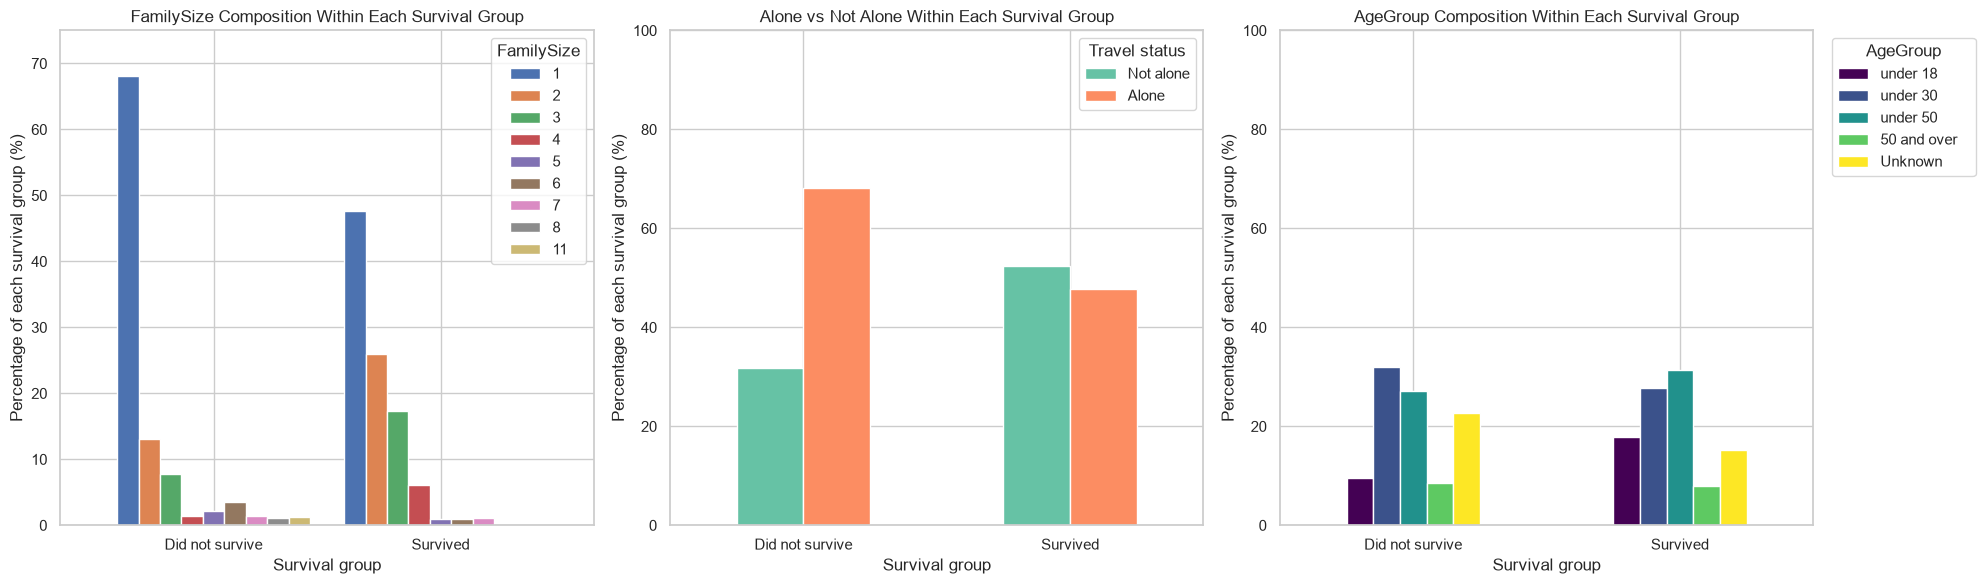

Percentage of each survival group by alone status:


Alone status,Not alone,Alone
Survival group,,
Did not survive,31.9,68.1
Survived,52.3,47.7


Percentage of each survival group by FamilySize:


FamilySize,1,2,3,4,5,6,7,8,11
Survival group,,,,,,,,,
Did not survive,68.1,13.1,7.8,1.5,2.2,3.5,1.5,1.1,1.3
Survived,47.7,26.0,17.3,6.1,0.9,0.9,1.2,0.0,0.0


Percentage of each survival group by AgeGroup:


AgeGroup,under 18,under 30,under 50,50 and over,Unknown
Survival group,,,,,
Did not survive,9.5,32.1,27.1,8.6,22.8
Survived,17.8,27.8,31.3,7.9,15.2


In [10]:


import matplotlib.pyplot as plt
import seaborn as sns
# Keep the existing feature table unchanged and calculate summaries for plotting.
plot_df = df_features.copy()
plot_df['Survival group'] = plot_df['Survived'].map({0: 'Did not survive', 1: 'Survived'})
plot_df['Alone status'] = plot_df['IsAlone'].map({0: 'Not alone', 1: 'Alone'})

sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. FamilySize composition: percentage of each survival group.
family_percent = (
    pd.crosstab(plot_df['Survival group'], plot_df['FamilySize'], normalize='index')
    .mul(100)
    .reindex(['Did not survive', 'Survived'])
    .reindex(columns=sorted(plot_df['FamilySize'].unique()))
)
family_percent.plot(kind='bar', ax=axes[0], width=0.85)
axes[0].set_title('FamilySize Composition Within Each Survival Group')
axes[0].set_xlabel('Survival group')
axes[0].set_ylabel('Percentage of each survival group (%)')
axes[0].set_ylim(0, 75)
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='FamilySize')

# 2. Alone/not alone: percentage of each survival group.
alone_percent = (
    pd.crosstab(plot_df['Survival group'], plot_df['Alone status'], normalize='index')
    .mul(100)
    .reindex(['Did not survive', 'Survived'])
    .reindex(columns=['Not alone', 'Alone'])
)
alone_percent.plot(kind='bar', ax=axes[1], color=['#66c2a5', '#fc8d62'])
axes[1].set_title('Alone vs Not Alone Within Each Survival Group')
axes[1].set_xlabel('Survival group')
axes[1].set_ylabel('Percentage of each survival group (%)')
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Travel status')

# 3. AgeGroup composition: percentage of each survival group.
age_order = ['under 18', 'under 30    ', 'under 50    ', '50 and over   ', 'Unknown']
age_percent = (
    pd.crosstab(plot_df['Survival group'], plot_df['AgeGroup'], normalize='index')
    .mul(100)
    .reindex(['Did not survive', 'Survived'])
    .reindex(columns=[age for age in age_order if age in plot_df['AgeGroup'].unique()], fill_value=0)
)
age_percent.plot(kind='bar', ax=axes[2], colormap='viridis')
axes[2].set_title('AgeGroup Composition Within Each Survival Group')
axes[2].set_xlabel('Survival group')
axes[2].set_ylabel('Percentage of each survival group (%)')
axes[2].set_ylim(0, 100)
axes[2].tick_params(axis='x', rotation=0)
axes[2].legend(title='AgeGroup', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

# These tables make the exact percentages visible next to the charts.
print('Percentage of each survival group by alone status:')
display(alone_percent.round(1))
print('Percentage of each survival group by FamilySize:')
display(family_percent.round(1))
print('Percentage of each survival group by AgeGroup:')
display(age_percent.round(1))

Set up three bar charts to compare family size, solo travel, and age groups. Each chart uses percentages within the survivor and non-survivor groups to compare the two groups even though they have different numbers of passengers.

Comparison of FamilySize and IsAlone across AgeGroup:


,Passengers,MeanFamilySize,MedianFamilySize,PercentAlone
AgeGroupClean,,,,
under 18,113,3.5,3.0,20.4
under 30,271,1.6,1.0,66.1
under 50,256,1.7,1.0,60.2
50 and over,74,1.6,1.0,64.9
Unknown,177,1.7,1.0,75.1


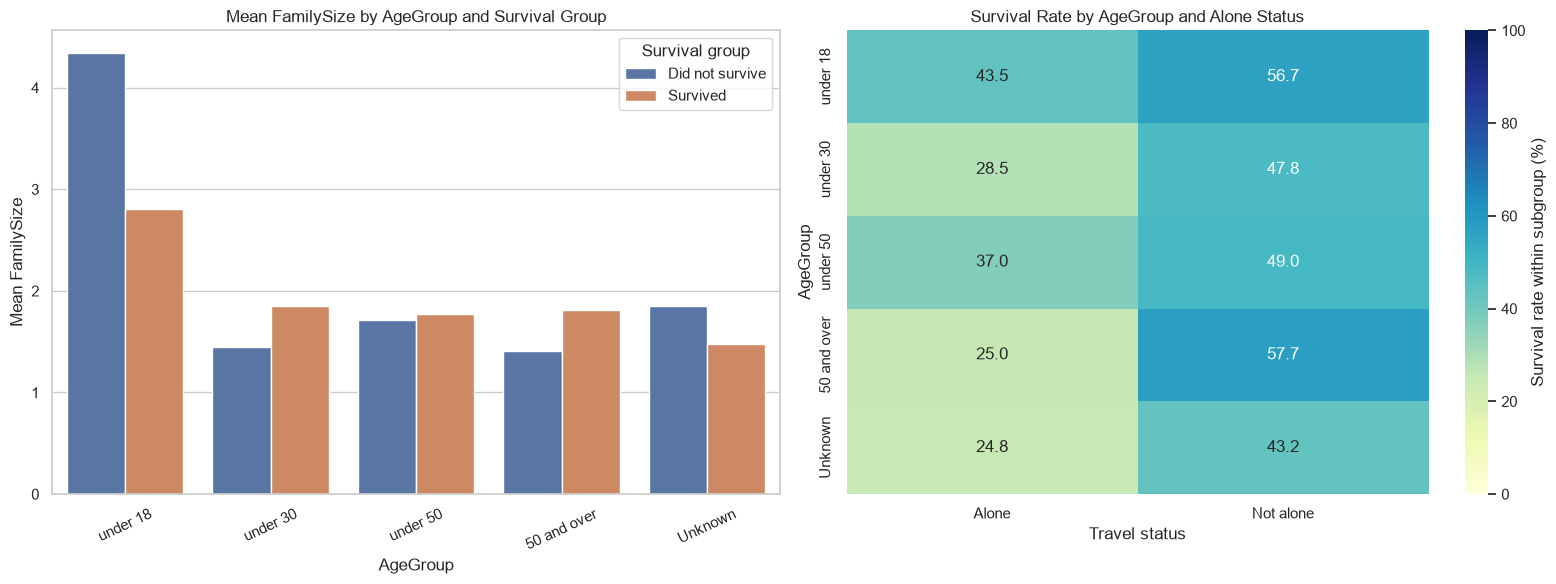

Survival-rate comparison: each cell is the percentage surviving within that AgeGroup × Alone-status subgroup.


Alone status,Alone,Not alone
AgeGroupClean,,
under 18,43.5,56.7
under 30,28.5,47.8
under 50,37.0,49.0
50 and over,25.0,57.7
Unknown,24.8,43.2


In [11]:
# Compare AgeGroup, FamilySize, and IsAlone together.
comparison_df = df_features.copy()
comparison_df['AgeGroupClean'] = comparison_df['AgeGroup'].str.strip()
comparison_df['Survival group'] = comparison_df['Survived'].map({0: 'Did not survive', 1: 'Survived'})
comparison_df['Alone status'] = comparison_df['IsAlone'].map({0: 'Not alone', 1: 'Alone'})

age_order = ['under 18', 'under 30', 'under 50', '50 and over', 'Unknown']
age_order = [age for age in age_order if age in comparison_df['AgeGroupClean'].unique()]

# One row per age group: family-size level, solo-travel share, and group size.
age_summary = (
    comparison_df.groupby('AgeGroupClean')
    .agg(
        Passengers=('FamilySize', 'size'),
        MeanFamilySize=('FamilySize', 'mean'),
        MedianFamilySize=('FamilySize', 'median'),
        PercentAlone=('IsAlone', lambda values: values.mean() * 100)
    )
    .reindex(age_order)
)
print('Comparison of FamilySize and IsAlone across AgeGroup:')
display(age_summary.round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: FamilySize compared across age groups and survival groups.
sns.barplot(
    data=comparison_df,
    x='AgeGroupClean',
    y='FamilySize',
    hue='Survival group',
    hue_order=['Did not survive', 'Survived'],
    order=age_order,
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title('Mean FamilySize by AgeGroup and Survival Group')
axes[0].set_xlabel('AgeGroup')
axes[0].set_ylabel('Mean FamilySize')
axes[0].tick_params(axis='x', rotation=25)
axes[0].legend(title='Survival group')

# Chart 2: Survival-rate comparison for alone vs not alone within each age group.
survival_comparison = (
    comparison_df.groupby(['AgeGroupClean', 'Alone status'])['Survived']
    .mean()
    .mul(100)
    .unstack('Alone status')
    .reindex(age_order)
)
sns.heatmap(
    survival_comparison,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    vmin=0,
    vmax=100,
    ax=axes[1],
    cbar_kws={'label': 'Survival rate within subgroup (%)'}
)
axes[1].set_title('Survival Rate by AgeGroup and Alone Status')
axes[1].set_xlabel('Travel status')
axes[1].set_ylabel('AgeGroup')

plt.tight_layout()
plt.show()

print('Survival-rate comparison: each cell is the percentage surviving within that AgeGroup × Alone-status subgroup.')
display(survival_comparison.round(1))

Comparison Analysis
grouped passengers by age to see how average family size and solo travel varied across age groups. I also calculated survival rates for passengers traveling alone and with family within each age group, then used a heatmap to show those rates side by side.

In [12]:

from datetime import datetime


class Passenger:
    """
    Represents a passenger with all their information.
    """
    def __init__(self, passenger_id, name, age, sex, survived, pclass, 
                 fare, embarked=None, family_size=None, is_alone=None, title=None, age_group=None):

        
        # TODO: Initialize all passenger attributes
        # Tip: Use pd.notna() to check if a value is not null/NaN
        # Tip: Convert to appropriate types (int, float, str)

        # Example for passenger_id:
        
        self.passenger_id = int(passenger_id) if pd.notna(passenger_id) else None
        self.name = str(name) if pd.notna(name) else None
        self.age = float(age) if pd.notna(age) else None
        self.sex = str(sex) if pd.notna(sex) else None
        self.survived = bool(survived) if pd.notna(survived) else None
        self.pclass = int(pclass) if pd.notna(pclass) else None
        self.fare = float(fare) if pd.notna(fare) else None
        self.embarked = str(embarked) if pd.notna(embarked) else None
        self.family_size = int(family_size) if pd.notna(family_size) else None
        self.is_alone = bool(is_alone) if pd.notna(is_alone) else None
        self.title = str(title) if pd.notna(title) else None
        self.age_group = str(age_group) if pd.notna(age_group) else None

    def to_dict(self):
        """Convert passenger to dictionary for JSON serialization."""
        # TODO: Return a dictionary with all passenger attributes
        # Tip: Dictionary keys should match the attribute names
        return {
            'passenger_id': self.passenger_id,
            'name': self.name,
            'age': self.age,
            'sex': self.sex,    
            'survived': self.survived,
            'pclass': self.pclass,  
            'fare': self.fare,
            'embarked': self.embarked,
            'family_size': self.family_size,
            'is_alone': self.is_alone,
            'title': self.title,
            'age_group': self.age_group

        }

class TitanicDataset:
    """
    Represents the entire Titanic dataset with methods for JSON export.
    """
    def __init__(self, dataframe):
        self.dataframe = dataframe
        self.passengers = []  # Will store Passenger objects
        self._create_passengers()
    
    def _create_passengers(self):
        """Create Passenger objects from dataframe."""
        for idx, row in self.dataframe.iterrows():
            passenger = Passenger(
                passenger_id = row.get('PassengerId', idx),
                name = row.get('Name', None),
                age = row.get('Age', None), 
                sex = row.get('Sex', None),
                survived = row.get('Survived', None),   
                pclass = row.get('Pclass', None),
                fare = row.get('Fare', None),   
                embarked = row.get('Embarked', None),
                family_size = row.get('FamilySize', None),
                is_alone = row.get('IsAlone', None),
                title = row.get('Title', None),
                age_group = row.get('AgeGroup', None)
            )
            self.passengers.append(passenger)


    def to_json(self, filename='titanic_data.json'):
        """Export dataset to JSON file."""
        missing_values = {}
        for col in self.dataframe.columns:
            count = int(self.dataframe[col].isna().sum())
            missing_values[col] = {
                'missing_count': count,
                'missing_percent': count / len(self.dataframe) * 100
            }

    
        # TODO: Create a dictionary with metadata and passenger data
        data = {
            'metadata': {
                'dataset_name': 'Titanic Passenger Dataset',
                'export_date': datetime.now().isoformat(), 
                'total_passengers': len(self.passengers), # Total_passengers from self.passengers
                'survival_rate': self.dataframe['Survived'].mean() #survival_rate
            },
            'passengers': [p.to_dict() for p in self.passengers],
            'statistics': self.get_summary_stats(),
            'descriptive_statistics': self.dataframe.select_dtypes(
                include='number'
            ).agg(['mean', 'median', 'std']).to_dict(),
            'missing_values': missing_values
        }
        with open(filename, 'w', encoding='utf-8') as file:
            json.dump(data, file, indent=2)   # TODO: Use json.dump() with indent=2 for readable formatting
        
        print(f"Data exported to {filename}")
        return data         

    def get_summary_stats(self):
        """Get summary statistics."""
        # TODO: Calculate and return summary statistics
        # Tip: Use list comprehensions to filter and calculate
        # Example for counting survived passengers:
        # survived_count = sum(1 for p in self.passengers if p.survived == 1)
        survived_count = sum(1 for p in self.passengers if p.survived)
        ages = [p.age for p in self.passengers if p.age is not None]
        fares = [p.fare for p in self.passengers if p.fare is not None]
        
        return {
            'total_passengers': len(self.passengers),
            'survived': survived_count,
            'did_not_survive': len(self.passengers) - survived_count,
            'average_age': sum(ages) / len(ages) if ages else None,
            'average_fare': sum(fares) / len(fares) if fares else None
            # TODO: Add more statistics (average_fare)

        }

if 'df_features' in locals() and not df_features.empty:
    titanic_dataset = TitanicDataset(df_features)
    print("Number of passengers:", len(titanic_dataset.passengers))
    summary_stats = titanic_dataset.get_summary_stats()
    for label, value in summary_stats.items():
        print(label, ":", value)
    

    # Export to JSON
    titanic_dataset.to_json(JSON_FILE)
 



    

Number of passengers: 891
total_passengers : 891
survived : 342
did_not_survive : 549
average_age : 29.69911764705882
average_fare : 32.204207968574636
Data exported to data\titanic_processed.json




I used the `Passenger` class to turn each row into a passenger record and convert it to a dictionary for export. I used the `TitanicDataset` class to collect those records, calculate summary statistics, and export the passenger data and dataset details to JSON.

In [13]:
print(JSON_FILE.resolve())

C:\Users\momin\OneDrive\Desktop\AIPT2026\my first repo computer\titanic_lab\data\titanic_processed.json


In [14]:
# Additional validation: Load and inspect JSON
with open(JSON_FILE, 'r', encoding='utf-8') as file:
    loaded_data = json.load(file)

print("Passengers in saved file:", len(loaded_data['passengers']))

Passengers in saved file: 891


In [15]:
with open(JSON_FILE, 'r', encoding='utf-8') as f:
    json_data = json.load(f)
    print(json_data['passengers'][0]['age_group'])

print(json_data.keys())

print(json_data['statistics'])
print(json_data['missing_values']['Age'])

under 30    
dict_keys(['metadata', 'passengers', 'statistics', 'descriptive_statistics', 'missing_values'])
{'total_passengers': 891, 'survived': 342, 'did_not_survive': 549, 'average_age': 29.69911764705882, 'average_fare': 32.204207968574636}
{'missing_count': 177, 'missing_percent': 19.865319865319865}


Path to JSON

Printed the full path to the JSON file so I could see exactly where the notebook saved it.

### Data-analyst interpretation

The revised FamilySize chart shows the composition of each survival group. Among passengers who did not survive, 68.1% had `FamilySize = 1`; among survivors, this was 47.7%. Conversely, `FamilySize = 2` represented 26.0% of survivors but 13.1% of non-survivors, and `FamilySize = 3` represented 17.3% of survivors but 7.8% of non-survivors. Very large families were uncommon in both groups, so their percentages should be interpreted cautiously.

The alone/not-alone chart supports the same pattern: 68.1% of non-survivors were travelling alone, compared with 47.7% of survivors. The age composition also differs: `under 18` passengers make up 17.8% of survivors but 9.5% of non-survivors, while passengers with unknown age make up 15.2% of survivors and 22.8% of non-survivors. The missing-age group is large, so age conclusions should be treated as incomplete rather than definitive.

Together, these results suggest that the survival groups had different mixes of family situation and age. They describe associations in this dataset; they do not show that FamilySize, IsAlone, or AgeGroup caused a passenger to survive.

### Additional features worth considering

- `Sex`: compare it with these features because survival may differ across sex while family structure and age also vary by sex.
- `Pclass`: use it as a proxy for ticket class and access to resources; it may help explain differences that FamilySize alone cannot.
- `Deck`: extract the first letter of `Cabin` to examine whether cabin location is associated with the outcomes; retain an `Unknown` category because most cabin values are missing.
- `TicketGroupSize`: count passengers sharing a ticket to distinguish a travelling group from the passenger's immediate family.

These features should be tested with tables and plots alongside the existing variables, while remembering that an association is not evidence of causation.

## Reflections

I created `FamilySize`, `IsAlone`, and `AgeGroup` to explore survival patterns.

Average family size was similar in both groups, but survivors were less likely to be traveling alone and more likely to be under 18 than non-survivors. 

A class can keep the data and the methods for preparing and exporting it to JSON together, making the code easier to reuse.